# Gradient Descent and Stochastic Gradient Descent

We minimize the objective

$$f(x)=\tfrac12 f_1(x)+\tfrac12 f_2(x)=x^3-3x+1,$$

where $f_1(x)=x^3-4x+1$ and $f_2(x)=x^3-2x+1$. Thus $f'(x)=3x^2-3$ and $f''(x)=6x$. The stationary points are $x=-1$ (a local maximum) and $x=1$ (a local minimum). Since $f(x)\to-\infty$ as $x\to-\infty$, the objective has no global minimizer.

Both methods use a fixed step size of $0.05$, tolerance $10^{-6}$ on the full objective gradient, and a cap of 1000 updates. SGD samples one component uniformly at random; its random seed is fixed so the run is reproducible. A run that reaches the cap or diverges before satisfying the tolerance is reported as not converged.

In [1]:
import math
import random
from html import escape
from IPython.display import HTML, SVG, display

ALPHA_GD = 0.05
ALPHA_SGD = 0.05
EPSILON = 1e-6
MAX_ITERATIONS = 1000

def f(x):
    return x*x*x - 3*x + 1

def grad_f(x):
    return 3*x*x - 3

def second_derivative(x):
    return 6*x

def f1(x):
    return x*x*x - 4*x + 1

def f2(x):
    return x*x*x - 2*x + 1

def grad_component(x, index):
    if index == 1:
        return 3*x*x - 4
    if index == 2:
        return 3*x*x - 2
    raise ValueError("Component index must be 1 or 2.")

assert math.isclose((f1(0.7) + f2(0.7)) / 2, f(0.7))
assert math.isclose((grad_component(0.7, 1) + grad_component(0.7, 2)) / 2, grad_f(0.7))
print(f"f'(x) = 3x^2 - 3; f''(x) = 6x")
print(f"GD step size = {ALPHA_GD}, SGD step size = {ALPHA_SGD}, tolerance = {EPSILON:g}, cap = {MAX_ITERATIONS}")

f'(x) = 3x^2 - 3; f''(x) = 6x
GD step size = 0.05, SGD step size = 0.05, tolerance = 1e-06, cap = 1000


In [2]:
def run_gd(x0, alpha=ALPHA_GD):
    x = float(x0)
    iterates = [x]
    status = "maximum iterations reached"
    updates = 0
    for _ in range(MAX_ITERATIONS):
        if not math.isfinite(x):
            status = "diverged (non-finite iterate)"
            break
        if abs(grad_f(x)) < EPSILON:
            status = "converged"
            break
        x -= alpha * grad_f(x)
        updates += 1
        iterates.append(x)
        if not math.isfinite(x):
            status = "diverged (non-finite iterate)"
            break
    else:
        if math.isfinite(x) and abs(grad_f(x)) < EPSILON:
            status = "converged"
    return {"method": "GD", "x0": x0, "alpha": alpha, "x": x,
            "iterations": updates, "iterates": iterates, "status": status}

def run_sgd(x0, alpha=ALPHA_SGD, seed=0):
    x = float(x0)
    iterates = [x]
    rng = random.Random(seed)
    status = "maximum iterations reached"
    updates = 0
    for _ in range(MAX_ITERATIONS):
        if not math.isfinite(x):
            status = "diverged (non-finite iterate)"
            break
        if abs(grad_f(x)) < EPSILON:
            status = "converged"
            break
        index = rng.choice((1, 2))
        x -= alpha * grad_component(x, index)
        updates += 1
        iterates.append(x)
        if not math.isfinite(x):
            status = "diverged (non-finite iterate)"
            break
    else:
        if math.isfinite(x) and abs(grad_f(x)) < EPSILON:
            status = "converged"
    return {"method": "SGD", "x0": x0, "alpha": alpha, "x": x,
            "iterations": updates, "iterates": iterates, "status": status}

runs = [
    run_gd(2.0),
    run_sgd(2.0, seed=2026),
    run_gd(-2.0),
    run_sgd(-2.0, seed=2027),
]

def classify_result(result):
    x = result["x"]
    if result["status"] != "converged" or not math.isfinite(x):
        return "Not stationary; no extremum classification"
    curvature = second_derivative(x)
    if curvature > 0:
        return "Local minimum (f'' > 0)"
    if curvature < 0:
        return "Local maximum (f'' < 0)"
    return "Inconclusive (f'' = 0)"

def format_number(value):
    if value is None:
        return "undefined (diverged)"
    return f"{value:.10g}" if math.isfinite(value) else str(value)

rows = []
for result in runs:
    result["objective"] = f(result["x"]) if math.isfinite(result["x"]) else None
    result["classification"] = classify_result(result)
    rows.append(result)

headers = ("Method", "x0", "alpha", "Iterations", "Final x*", "Classification", "f(x*)", "Status")
table = "<table><thead><tr>" + "".join(f"<th>{escape(h)}</th>" for h in headers) + "</tr></thead><tbody>"
for r in rows:
    values = (r["method"], format_number(r["x0"]), format_number(r["alpha"]),
              str(r["iterations"]), format_number(r["x"]), r["classification"],
              format_number(r["objective"]), r["status"])
    table += "<tr>" + "".join(f"<td>{escape(v)}</td>" for v in values) + "</tr>"
table += "</tbody></table>"
display(HTML(table))

Method,x0,alpha,Iterations,Final x*,Classification,f(x*),Status
GD,2,0.05,43,1.000000121,Local minimum (f'' > 0),-1,converged
SGD,2,0.05,1000,0.9621394226,Not stationary; no extremum classification,-0.9957540003,maximum iterations reached
GD,-2,0.05,15,-inf,Not stationary; no extremum classification,undefined (diverged),diverged (non-finite iterate)
SGD,-2,0.05,15,-inf,Not stationary; no extremum classification,undefined (diverged),diverged (non-finite iterate)


## Objective and iterate plots

Each panel shows the objective and the corresponding iteration path. The displayed window is limited to keep the objective's local features visible; diverging paths that leave the window are noted in their panel.

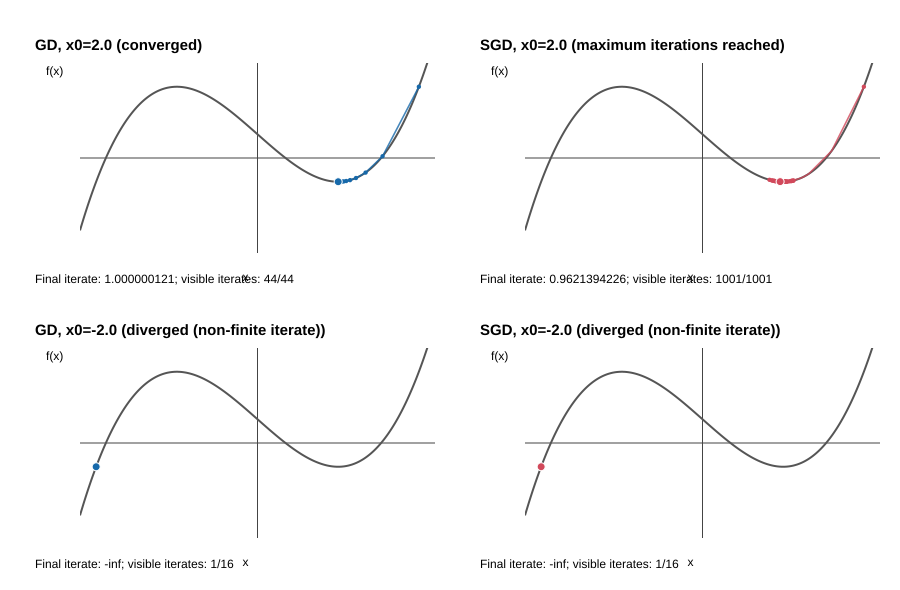

In [3]:
def make_plot(runs):
    width, height = 900, 590
    panel_w, panel_h = 420, 250
    x_min, x_max = -2.2, 2.2
    y_min, y_max = -4.0, 4.0
    colors = {"GD": "#1769aa", "SGD": "#d1495b"}
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
             '<rect width="100%" height="100%" fill="white"/>',
             '<style>text{font-family:Arial,sans-serif;font-size:12px}.title{font-size:15px;font-weight:bold}.axis{stroke:#444;stroke-width:1}.curve{fill:none;stroke:#555;stroke-width:2}.path{fill:none;stroke-width:1.6;opacity:.8}</style>']
    for i, result in enumerate(runs):
        col, row = i % 2, i // 2
        left, top = 35 + col * 445, 35 + row * 285
        plot_left, plot_top = left + 45, top + 28
        plot_w, plot_h = panel_w - 65, panel_h - 60
        sx = lambda x: plot_left + (x - x_min) / (x_max - x_min) * plot_w
        sy = lambda y: plot_top + (y_max - y) / (y_max - y_min) * plot_h
        clip_id = f"clip{i}"
        parts.append(f'<defs><clipPath id="{clip_id}"><rect x="{plot_left}" y="{plot_top}" width="{plot_w}" height="{plot_h}"/></clipPath></defs>')
        parts.append(f'<text class="title" x="{left}" y="{top + 15}">{result["method"]}, x0={result["x0"]} ({result["status"]})</text>')
        parts.append(f'<line class="axis" x1="{plot_left}" y1="{sy(0)}" x2="{plot_left + plot_w}" y2="{sy(0)}"/><line class="axis" x1="{sx(0)}" y1="{plot_top}" x2="{sx(0)}" y2="{plot_top + plot_h}"/>')
        curve = []
        for j in range(301):
            x = x_min + (x_max - x_min) * j / 300
            y = f(x)
            curve.append(f"{sx(x):.2f},{sy(y):.2f}")
        parts.append(f'<polyline class="curve" clip-path="url(#{clip_id})" points="{" ".join(curve)}"/>')
        points = []
        for x in result["iterates"]:
            if math.isfinite(x):
                y = f(x) if abs(x) < 1e100 else math.inf
                points.append((x, y))
        visible = [(x, y) for x, y in points if x_min <= x <= x_max and y_min <= y <= y_max]
        if visible:
            path = " ".join(f"{sx(x):.2f},{sy(y):.2f}" for x, y in visible)
            parts.append(f'<polyline class="path" stroke="{colors[result["method"]]}" clip-path="url(#{clip_id})" points="{path}"/>')
            stride = max(1, len(visible) // 35)
            for x, y in visible[::stride]:
                parts.append(f'<circle cx="{sx(x):.2f}" cy="{sy(y):.2f}" r="2.2" fill="{colors[result["method"]]}"/>')
            x_last, y_last = visible[-1]
            parts.append(f'<circle cx="{sx(x_last):.2f}" cy="{sy(y_last):.2f}" r="4" fill="{colors[result["method"]]}" stroke="white" stroke-width="1"/>')
        parts.append(f'<text x="{plot_left + plot_w/2 - 15}" y="{plot_top + plot_h + 28}">x</text><text x="{plot_left - 34}" y="{plot_top + 12}">f(x)</text>')
        parts.append(f'<text x="{left}" y="{top + panel_h - 2}">Final iterate: {escape(format_number(result["x"]))}; visible iterates: {len(visible)}/{len(result["iterates"])}</text>')
    parts.append('</svg>')
    return "".join(parts)

display(SVG(make_plot(runs)))

## Discussion

- **Convergence and stability:** From $x_0=2$, GD approaches the local minimum at $x=1$ smoothly. Fixed-step SGD is noisier because each component gradient differs from the full gradient; with a constant step size it may fluctuate around the minimum and fail the strict full-gradient tolerance within 1000 updates. The table records the actual outcome.
- **Starting at $x_0=-2$:** Both component gradients and the full gradient are positive for $x<-2$. The descent update therefore moves $x$ farther left, where the cubic objective decreases without bound. Both methods diverge rather than reach a minimizer; this is consistent with the objective having no global minimum.
- **Step-size sensitivity:** Near $x=1$, the GD error is approximately multiplied by $1-6\alpha$ per step, so local stability requires $0<\alpha<1/3$. A larger step can overshoot or become unstable, while a smaller step slows convergence. For constant-step SGD, reducing $\alpha$ reduces the size of random fluctuations but also slows progress; increasing it worsens noise and can destabilize the iteration. The fixed-step SGD run is not guaranteed to satisfy an arbitrarily tight tolerance.